# VERDE - EfficientNet-B0: Training Strategy Ablation (3.0 data)
### Smart Recycling and Waste Segregation Assistant - frozen vs fine-tuned and resampling vs class weights, three seeds each, on the 3.0 waste photos

**Question:** How should EfficientNet-B0 be trained for VERDE on the 3.0 data: with a frozen or a fine-tuned backbone, and with resampling or class-weighted loss, is the winner clearly better than the seed-to-seed noise, and do the 2.0 conclusions still hold?

**Answer:** Fine-tuning the whole network is essential and the way class imbalance is handled is not, on the 3.0 data as on 2.0. Fine-tuned runs (T3, T4) score 93.0% on the whole 3.0 test set (macro-F1 0.928) against 82.9 to 83.2% for frozen runs, and 93.8% against 79 to 80% on RealWaste. Resampling and class weights are a tie: T3 and T4 have the same accuracy and macro-F1, and the differences between them are inside the seed noise. The rule selected T3 seed 42 (validation F1 0.9234 against 0.9228 for T4). Training on 3.0 instead of 2.0 did not clearly help the fine-tuned models on the 2.0 test images (T3 -0.3 points, T4 +0.1, inside the noise) and made the frozen models worse by 1.6 to 2.3 points. On our 24 real photos the frozen models scored higher (54 to 62%) than the fine-tuned ones (46 to 50%), but 24 photos cannot separate them and several labels need a decision (see Section 9).


<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is being tested and why the result can be trusted.

**Why this model:** EfficientNet-B0 was the best model in the 3.0 benchmarks (93.0% test accuracy, macro-F1 0.928, 93.3% on RealWaste, 16 MB, 37 ms on the Kaggle CPU) and the model the benchmark rule chose in both 2.0 and 3.0. Because it is the leading candidate for the Pi, it gets the full ablation: 4 configurations x 3 seeds = 12 runs.

**What is different from the earlier benchmark notebooks**

| Earlier benchmark | This notebook |
|---|---|
| One run per model (seed 42) | **Three runs per configuration** (seeds 42, 7, 123), reported as mean ± standard deviation, so a gap can be compared with the noise |
| Final model chosen with the test set | Configuration and model chosen with the **validation set only**; the test set is only reported |
| One fixed training recipe | Four configurations (T1 to T4) compared on the same model, so the training strategy itself is tested |

**What is different from the 2.0 ablation:** the data. Training uses the 3.0 data (43,276 training images, 4.3 times the 10,096 of 2.0, from five sources instead of three); validation and test are the 3.0 sets (9,274 images each). The test set is also reported on the **2.0 test images alone** (2,164 images, identical to the 2.0 ablation's test set), so the two ablations can be compared like for like. Everything else (four configurations, three seeds, the recipe, selection by validation) is unchanged. Configuration T4 is the benchmark recipe, so T4 with seed 42 should land close to the 3.0 benchmark result for this model (93.0% on the whole test set, macro-F1 0.928); a large difference would point to a problem.

**The four training configurations** (all four are run in this notebook; they are set in `CONFIGS`, Section 5):

| Config | Backbone | Class imbalance handled by |
|---|---|---|
| T1 | Frozen (only the new output layer learns) | Resampling: rare classes are drawn more often, loss is unweighted |
| T2 | Frozen | Class-weighted loss: rare classes count more in the loss |
| T3 | Fine-tuned (all layers learn) | Resampling |
| T4 | Fine-tuned | Class-weighted loss (**the recipe used in the benchmark notebooks**) |

In every configuration, RealWaste photos are also drawn twice as often (`REALWASTE_BOOST = 2`), because they are the closest to what the Pi camera sees.

**Fixed for every run:** same 3.0 split, augmentation, AdamW (learning rate 3e-4, weight decay 1e-4), cosine schedule, 12 epochs, label smoothing 0.1, batch size 64, ImageNet weights as the starting point. The best epoch of each run is chosen by validation macro-F1.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Frozen backbone | The pretrained layers are kept as they are; only the last layer is trained |
| Fine-tuned | All layers are trained, starting from the pretrained weights |
| Resampling | Changing how often each photo is shown, so rare classes appear as often as common ones |
| Class-weighted loss | Mistakes on rare classes cost more in the loss (3.0 weights: 0.61 for `special` to 1.66 for `general`) |
| Seed | The number that fixes the random choices; different seeds give slightly different results |
| Validation vs test | Validation photos are used to make choices; test photos are only used to report the final score |
| Macro-F1 | One score in which every class counts equally |

<a id="section-2"></a>
## Section 2: Setup and Data

**Goal:** Load the exact split and class order created in the 3.0 data analysis notebook, so every run uses the same images and no test photo leaks into training.

**Before you run:** attach two inputs to this notebook: the output of **VERDE Data Analysis 3.0** (it holds `final_dataset_v3_std.csv`, `dataset_card_v3.json` and `verde_std_new/`) and the output of **VERDE Data Analysis 2.0** (it holds `verde_std/` with the 2.0 images). Optionally attach your real-photo dataset (file names such as `glass_bottle_01.jpg`; attach only your own photos) for the automatic score in Section 9. To continue an unfinished session, also attach that session's saved output (Section 5).

In [1]:
# ============================================================
# CELL 1 - SETUP AND DATA
# ============================================================

import json, random, time, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import torchvision.models as tvm
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
INPUT = Path("/kaggle/input")
OUT = Path("/kaggle/working")

def find_folder(marker, max_depth=4):
    """Folder under /kaggle/input that contains the file `marker`."""
    for depth in range(1, max_depth + 1):
        hits = sorted(INPUT.glob("/".join(["*"] * depth) + "/" + marker))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(f"{marker} not found under {INPUT}: attach the matching data-analysis notebook output "
                            f"in the Input panel.")

ROOT3 = find_folder("dataset_card_v3.json")        # VERDE Data Analysis 3.0 output
ROOT2 = find_folder("final_dataset_std.csv")       # VERDE Data Analysis 2.0 output
print("3.0 data:", ROOT3)
print("2.0 images:", ROOT2)

card = json.load(open(ROOT3 / "dataset_card_v3.json"))
class_names = card["classes"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

df = pd.read_csv(ROOT3 / "final_dataset_v3_std.csv")
IMG_DIR = {"v2": ROOT2 / "verde_std", "new": ROOT3 / "verde_std_new"}
df["img"] = df["origin"].map(lambda o: str(IMG_DIR[o])) + "/" + df["rel_path"]
df["y"] = df["final_class"].map(class_to_idx)

# Fail early, with a clear message, if an image folder is not attached
for o in ["v2", "new"]:
    sample = df[df["origin"] == o].sample(min(200, (df["origin"] == o).sum()), random_state=SEED)["img"]
    missing = [p for p in sample if not Path(p).exists()]
    assert not missing, f"{len(missing)} of {len(sample)} sampled '{o}' images are missing, e.g. {missing[0]}"

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}  (total {len(df)})")
print("Classes:", class_to_idx)
display(pd.crosstab(df["src"], df["split"], margins=True))
display(pd.crosstab(df["final_class"], [df["origin"], df["split"]]).reindex(class_names))


3.0 data: /kaggle/input/notebooks/tanveerdalal/verde-data-analysis-3-0
2.0 images: /kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0
Train: 43276  Val: 9274  Test: 9274  (total 61824)
Classes: {'food_garden': 0, 'general': 1, 'glass': 2, 'metal': 3, 'paper_card': 4, 'plastic': 5, 'special': 6, 'textile': 7}


split,test,train,val,All
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
GWD,5317,24815,5317,35449
HF,1793,8365,1793,11951
RealWaste,688,3306,756,4750
All,9274,43276,9274,61824


origin        new               v2           
split        test train   val test train  val
final_class                                  
food_garden   733  3419   732  283  1318  282
general       480  2241   480  216  1008  216
glass         495  2313   496  267  1248  268
metal         802  3740   802  282  1313  281
paper_card   1053  4915  1053  324  1513  324
plastic       980  4571   979  309  1441  309
special      1758  8206  1759  149   696  150
textile       809  3775   809  334  1559  334

**Finding:** The split loads as 43,276 training, 9,274 validation and 9,274 test images in 8 classes, and the 2.0 rows keep their 2.0 split (2,164 test images, 7,110 new). GlobalWasteData is 57% of the data, Hugging Face 19% and RealWaste, the real floor-photo source closest to the Pi camera, only 7.7% (4,750 of 61,824). `special` is the largest class, but only 149 of its test images come from 2.0 (against 1,758 new), so the 2.0 test set says little about `special`.

<a id="section-3"></a>
## Section 3: Data Pipeline

**Goal:** Turn the photos into batches, with augmentation that weakens background and lighting shortcuts, and with two selectable ways of handling class imbalance (resampling or class-weighted loss).

In [2]:
# WHAT: Define the transforms, the Dataset, the loaders, and make_train_loader(imbalance, seed).
# WHY:  Augmentation (zoom, rotation, colour change, greyscale) makes background and lighting
#       cues unreliable. Validation and test photos are never augmented. Class imbalance can
#       be handled in two ways, and this notebook compares them: "resample" changes how often
#       each photo is drawn, "classweights" keeps the draw as it is and weights the loss.
#       Both draw RealWaste photos twice as often (REALWASTE_BOOST), because they are the
#       closest to Pi photos.
# HOW:  WeightedRandomSampler draws photos with a weight each. For "resample" the weight is
#       also divided by the class's photo count, so every class is drawn about equally often.
#       The sampler's random draws are fixed by the seed given.
# ------------------------------------------------------------------------------------

IMG_SIZE = card["image_size"]            # 224
MEAN, STD = card["mean"], card["std"]    # ImageNet normalisation

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(mean=MEAN, std=STD)])

class WasteDataset(Dataset):
    """One photo per row of a split table, with a transform applied."""
    def __init__(self, frame, transform):
        self.paths = frame["img"].tolist()
        self.labels = frame["y"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[i]

BATCH_SIZE = 64            # if CUDA runs out of memory, use 32
REALWASTE_BOOST = 2.0
NUM_WORKERS = 4

def make_train_loader(imbalance, seed):
    """A new training loader. imbalance is "classweights" or "resample"."""
    w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
    if imbalance == "resample":
        counts = np.bincount(train_df["y"].to_numpy(), minlength=len(class_names))
        w = w / counts[train_df["y"].to_numpy()]
    g = torch.Generator()
    g.manual_seed(seed)
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True,
                                    generator=g)
    return DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                      sampler=sampler, drop_last=True, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=True)

val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(WasteDataset(test_df, eval_transform), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Check: how often each class is drawn under each option (seed 42)
for option in ["classweights", "resample"]:
    drawn = train_df["y"].to_numpy()[list(make_train_loader(option, 42).sampler)]
    share = np.bincount(drawn, minlength=len(class_names)) / len(drawn)
    print(f"{option:12s}", {c: f"{s:.0%}" for c, s in zip(class_names, share)})

classweights {'food_garden': '11%', 'general': '8%', 'glass': '8%', 'metal': '12%', 'paper_card': '15%', 'plastic': '14%', 'special': '19%', 'textile': '12%'}
resample     {'food_garden': '13%', 'general': '13%', 'glass': '13%', 'metal': '13%', 'paper_card': '13%', 'plastic': '13%', 'special': '12%', 'textile': '12%'}


**Finding:** With class weights the draw follows the natural class shares, so `special` is the largest class at 19% of each epoch and `general` and `glass` the smallest at 8% each. With resampling every class is drawn 12 to 13% of the time. This is the reverse of 2.0, where `special` was the rarest class (5%): in 3.0 the class-weighted loss gives `special` the smallest weight (0.61) and `general` the largest (1.66), so T3 and T4 treat the classes quite differently, and Section 7 shows whether that matters.

<a id="section-4"></a>
## Section 4: The Model

**Goal:** Build EfficientNet-B0 with an 8-class output layer, add the option of freezing everything except that layer, and measure its size and CPU speed. Speed is measured with 4 threads, like the four cores of a Raspberry Pi 5. A Kaggle CPU is faster than a Pi, so use the time only for comparison.

In [3]:
# WHAT: Define build_model(), the freeze option, and measure parameters, file size and CPU time.
# WHY:  The Pi has no GPU, so size and CPU time are the real cost of a model. Freezing the
#       backbone tests how much of the result comes from ImageNet features alone, and how
#       much comes from adapting the whole network to waste photos.
# HOW:  The last Linear layer (1000 ImageNet classes) is replaced by an 8-class layer.
#       Freezing sets requires_grad = False on every layer except that new layer.
# ------------------------------------------------------------------------------------

MODEL = "effnet_b0"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def build_model(pretrained=True):
    """EfficientNet-B0 with an 8-class output layer."""
    weights = tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    net = tvm.efficientnet_b0(weights=weights)
    head = head_of(net)
    new_head = nn.Linear(head.in_features, len(class_names))
    if hasattr(net, "fc"):                       # ResNet: the last layer is called fc
        net.fc = new_head
    else:                                        # MobileNet / EfficientNet: inside classifier
        last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
        net.classifier[last] = new_head
    return net

def head_of(net):
    """The output layer (the only part that learns when the backbone is frozen)."""
    if hasattr(net, "fc"):
        return net.fc
    last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
    return net.classifier[last]

def apply_backbone(net, backbone):
    """backbone is "finetune" (all layers learn) or "frozen" (only the output layer learns)."""
    for p in net.parameters():
        p.requires_grad = (backbone == "finetune")
    for p in head_of(net).parameters():
        p.requires_grad = True

def cpu_ms_per_photo(threads=4, runs=40):
    """Average CPU time for one 224x224 photo."""
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    net = build_model(pretrained=False).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(8):
            net(x)
        t = time.perf_counter()
        for _ in range(runs):
            net(x)
    torch.set_num_threads(old)
    return (time.perf_counter() - t) / runs * 1000

net = build_model(pretrained=False)
n_all = sum(p.numel() for p in net.parameters())
apply_backbone(net, "frozen")
n_head = sum(p.numel() for p in net.parameters() if p.requires_grad)
del net
spec = pd.Series({"parameters (M)": n_all / 1e6,
                  "trained when frozen (k)": n_head / 1e3,
                  "file size (MB)": n_all * 4 / 1e6,
                  "CPU ms/photo": cpu_ms_per_photo()}).round(2)
display(spec.to_frame(MODEL))

Using device: cuda


,effnet_b0
parameters (M),4.02
trained when frozen (k),10.25
file size (MB),16.07
CPU ms/photo,38.80


**Finding:** EfficientNet-B0 has 4.02 M parameters, a 16.07 MB file and 37.3 ms per photo on 4 CPU threads of the Kaggle CPU, the same as in 2.0 and in the 3.0 benchmark (these numbers do not depend on the data). With a frozen backbone only the 10.25 k weights of the output layer are trained. The Pi will be slower, so the real time must be measured on the device.

<a id="section-5"></a>
## Section 5: Training

**Goal:** Train every configuration with three seeds and keep the best checkpoint of each run, chosen by validation macro-F1.

**Time:** In 2.0 each run took about 10.5 minutes (frozen) or 12 (fine-tuned). With 4.3 times as many training images, expect about 45 minutes for a frozen run and about 48 for a fine-tuned run (the benchmark's single B0 run took 47.8), so about 9 hours for all 12 runs. Runs are saved one by one, in the order T4, T3, T1, T2 (the benchmark recipe first), and the notebook stops by itself before the session limit (`TIME_BUDGET_HOURS`, 11). If it stops early it prints what is left; save the output, attach it as an input to a new session of this notebook and run again, and the finished runs are copied and skipped. To run fewer runs, shorten `SEEDS` or `CONFIGS` in the next cell.

In [4]:
# WHAT: Define one training run, train_run(config, seed), and the checkpoint file names.
# WHY:  Each run has the same recipe except what the configuration changes. Using three
#       seeds shows how much a result moves by chance, so a difference between
#       configurations can be judged against that noise. The best epoch is chosen on the
#       validation set, so the test set stays untouched until reporting.
# HOW:  File names start with verde3_ so they cannot be mixed up with the 2.0 checkpoints.
#       A frozen backbone is kept in evaluation mode, so its BatchNorm statistics and
#       dropout stay fixed too. The checkpoint stores the configuration, seed and model name
#       next to the weights, so later notebooks can rebuild and identify it from the file.
# ------------------------------------------------------------------------------------

EPOCHS = 12
SEEDS = [42, 7, 123]
CONFIGS = {
    "T1": {"backbone": "frozen",   "imbalance": "resample"},
    "T2": {"backbone": "frozen",   "imbalance": "classweights"},
    "T3": {"backbone": "finetune", "imbalance": "resample"},
    "T4": {"backbone": "finetune", "imbalance": "classweights"},   # = the benchmark recipe
}
RUN_ORDER = ["T4", "T3", "T1", "T2"]   # the benchmark recipe first, so a stopped session still has it
assert sorted(RUN_ORDER) == sorted(CONFIGS)

class_w = torch.tensor(card["class_weights_v3_train"], dtype=torch.float32, device=device)
eval_criterion = nn.CrossEntropyLoss()

def make_criterion(imbalance):
    """Class-weighted loss for "classweights"; plain loss for "resample". Smoothing 0.1."""
    w = class_w if imbalance == "classweights" else None
    return nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)

def run_epoch(model, loader, criterion, optimizer=None, backbone="finetune"):
    """One pass over a loader. Trains if an optimiser is given, otherwise evaluates."""
    train = optimizer is not None
    if train and backbone == "finetune":
        model.train()
    else:
        model.eval()                  # evaluation, or a frozen backbone during training
    total, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            preds += out.argmax(1).cpu().tolist()
            labels += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return total / n, acc, np.array(preds), np.array(labels)

def ckpt_path(cfg, seed):
    return OUT / f"verde3_{MODEL}_{cfg}_s{seed}.pth"

def train_run(cfg, seed):
    """Train one configuration with one seed; return its history and training time."""
    c = CONFIGS[cfg]
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

    model = build_model().to(device)
    apply_backbone(model, c["backbone"])
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = make_criterion(c["imbalance"])
    train_loader = make_train_loader(c["imbalance"], seed)

    hist = {"train_acc": [], "val_acc": [], "val_f1": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, EPOCHS + 1):
        _, tr_acc, _, _ = run_epoch(model, train_loader, criterion, optimizer, c["backbone"])
        _, va_acc, vp, vy = run_epoch(model, val_loader, eval_criterion)
        va_f1 = f1_score(vy, vp, average="macro")
        scheduler.step()
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        hist["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1, mark = va_f1, " <- best"
            torch.save({"model_state": model.state_dict(), "class_names": class_names,
                        "arch": MODEL, "config": cfg, "backbone": c["backbone"],
                        "imbalance": c["imbalance"], "seed": seed, "epoch": epoch,
                        "val_acc": va_acc, "val_f1": va_f1, "data": "3.0"}, ckpt_path(cfg, seed))
        if epoch in (1, 4, 8, EPOCHS) or mark:
            print(f"  {cfg} s{seed} epoch {epoch:2d}/{EPOCHS}  train {tr_acc:.1%}  "
                  f"val {va_acc:.1%}  F1 {va_f1:.3f}{mark}")

    del model, optimizer, train_loader
    torch.cuda.empty_cache()
    return {"history": hist, "minutes": (time.time() - t0) / 60}

In [5]:
# WHAT: Run every configuration with every seed and keep the histories in effnet_b0_runs3.json.
# WHY:  Training takes hours. Results are saved after each run, a run that is already done
#       is skipped, finished runs of an earlier session are copied in if that session's output
#       is attached, and the loop stops before the 12-hour Kaggle limit, so no work is lost.
#       Delete effnet_b0_runs3.json (and the verde3_*.pth files) to retrain from scratch. If an
#       "Exception ignored" message from the data loader appears, it is harmless.
# HOW:  Two loops; a printed line shows the best-so-far epochs of each run. After the loops,
#       CONFIGS is cut down to the configurations whose seeds are all finished.
# ------------------------------------------------------------------------------------

RUNS_PATH = OUT / f"{MODEL}_runs3.json"
runs = json.load(open(RUNS_PATH)) if RUNS_PATH.exists() else {}

# --- Continue from an earlier session ---------------------------------------------------
# If the saved output of an earlier session of this notebook is attached as an input, its
# finished runs (histories and checkpoints) are copied here and skipped below.
pulled = 0
for depth in range(1, 5):
    for f in sorted(INPUT.glob("/".join(["*"] * depth) + f"/{MODEL}_runs3.json")):
        for key, val in json.load(open(f)).items():
            cfg_, seed_ = key.split("_s")
            src_ck = f.parent / ckpt_path(cfg_, int(seed_)).name
            if key not in runs and src_ck.exists():
                shutil.copy(src_ck, ckpt_path(cfg_, int(seed_)))
                runs[key] = val
                pulled += 1
if pulled:
    json.dump(runs, open(RUNS_PATH, "w"))
    print(f"Continuing: {pulled} finished runs copied from an earlier session's output.")

# --- Train every run that is not finished yet --------------------------------------------
TIME_BUDGET_HOURS = 11.0         # Kaggle stops a session at 12 hours; stop cleanly before that
t_start, longest, out_of_time = time.time(), 0.0, False
for cfg in RUN_ORDER:
    for seed in SEEDS:
        key = f"{cfg}_s{seed}"
        if key in runs and ckpt_path(cfg, seed).exists():
            print(f"Skipping {key}: already trained")
            continue
        elapsed = (time.time() - t_start) / 60
        if longest and elapsed + 1.1 * longest > TIME_BUDGET_HOURS * 60:
            out_of_time = True
            break
        print(f"\n=== Training {MODEL} {key} ({CONFIGS[cfg]['backbone']}, "
              f"{CONFIGS[cfg]['imbalance']}) ===")
        runs[key] = train_run(cfg, seed)
        longest = max(longest, runs[key]["minutes"])
        json.dump(runs, open(RUNS_PATH, "w"))
        print(f"{key}: best val F1 {max(runs[key]['history']['val_f1']):.3f}, "
              f"{runs[key]['minutes']:.1f} min")
    if out_of_time:
        break

# --- What is finished? Later sections use only the configurations with all seeds done ---
CONFIGS_ALL = dict(CONFIGS)
left = [f"{c}_s{s}" for c in CONFIGS_ALL for s in SEEDS if f"{c}_s{s}" not in runs]
CONFIGS = {c: v for c, v in CONFIGS_ALL.items() if all(f"{c}_s{s}" in runs for s in SEEDS)}
if left:
    print(f"\nNOT FINISHED: {len(left)} of {len(CONFIGS_ALL) * len(SEEDS)} runs are still to do: {left}")
    print("Save this session's output, attach it as an input to a new session of this notebook and run it again:")
    print("the finished runs are copied and skipped. Sections 6 to 9 below use only the finished configurations:",
          list(CONFIGS))
assert CONFIGS, "No configuration has finished all its seeds yet: run the training cell again (with the earlier output attached)."



=== Training effnet_b0 T4_s42 (finetune, classweights) ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 170MB/s]


  T4 s42 epoch  1/12  train 78.9%  val 85.5%  F1 0.851 <- best


  T4 s42 epoch  2/12  train 87.5%  val 87.9%  F1 0.874 <- best


  T4 s42 epoch  3/12  train 90.4%  val 89.3%  F1 0.889 <- best


  T4 s42 epoch  4/12  train 92.4%  val 90.7%  F1 0.904 <- best


... (117 outputs left out)

  T2 s123 epoch  6/12  train 80.4%  val 81.9%  F1 0.811 <- best


  T2 s123 epoch  8/12  train 81.1%  val 81.7%  F1 0.809


  T2 s123 epoch  9/12  train 80.7%  val 81.9%  F1 0.811 <- best


  T2 s123 epoch 12/12  train 81.2%  val 81.9%  F1 0.811
T2_s123: best val F1 0.811, 35.2 min


**Finding:** All 12 runs finished in one session (8.4 hours, against the estimate of 9). Best validation macro-F1 was 0.811 to 0.817 for the frozen runs (T1, T2) and 0.922 to 0.925 for the fine-tuned runs (T3, T4), and it varies by at most 0.003 within a configuration, so the seeds agree closely. Frozen runs took 34.2 to 35.1 minutes and fine-tuned runs 47.6 to 48.0 minutes (T4 seed 42 took 54.8, probably a slower Kaggle machine), so freezing saves about 27 to 31% of the time, a larger saving than in 2.0 (14%). The best epoch was 8 to 12 in every run.

<a id="section-6"></a>
## Section 6: Learning Curves

**Goal:** Check whether the runs learn steadily, whether they overfit, and whether 12 epochs were enough.

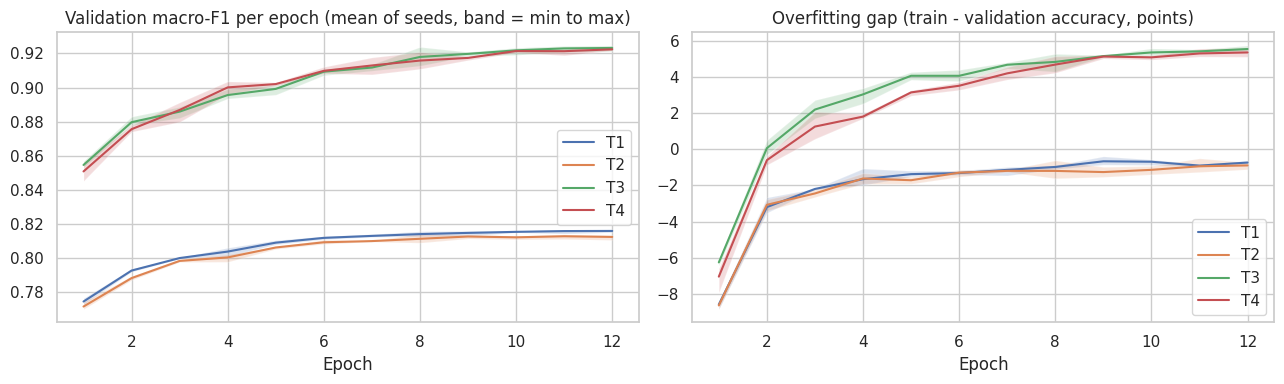

In [6]:
# WHAT: Plot the validation macro-F1 per epoch and the overfitting gap, averaged over seeds.
# WHY:  A gap that widens between training and validation accuracy is the standard sign of
#       overfitting. A frozen backbone should overfit less because far fewer weights learn.
#       If validation is still rising at epoch 12, more epochs could help.
# HOW:  One line per configuration: the mean over seeds, with the lowest and highest seed
#       shown as a shaded band. Gap = training accuracy minus validation accuracy, in points.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cfg in CONFIGS:
    keys = [f"{cfg}_s{s}" for s in SEEDS]
    f1 = np.array([runs[k]["history"]["val_f1"] for k in keys])
    gap = np.array([np.array(runs[k]["history"]["train_acc"]) -
                    np.array(runs[k]["history"]["val_acc"]) for k in keys]) * 100
    ep = np.arange(1, f1.shape[1] + 1)
    for ax, arr in zip(axes, [f1, gap]):
        ax.plot(ep, arr.mean(0), label=cfg)
        ax.fill_between(ep, arr.min(0), arr.max(0), alpha=0.2)
axes[0].set_title("Validation macro-F1 per epoch (mean of seeds, band = min to max)")
axes[1].set_title("Overfitting gap (train - validation accuracy, points)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Frozen runs level off at about epoch 6 to 8 at a validation macro-F1 of 0.81 to 0.82, and their train-validation gap stays below zero (about -1 point at epoch 12: training accuracy is lower than validation accuracy because the training photos are augmented). They never overfit; the frozen features are simply not enough, as in 2.0 but at a lower level. Fine-tuned runs start at about 0.85 in epoch 1, rise steeply until epoch 6 (about 0.91) and then creep up, with only +0.004 gained over the last three epochs of T3; the gap grows from about -6 points in epoch 1 to about +5.5 at epoch 12 (98.2% training against 92.6% validation for T3). That gap is about the same as in 2.0 (about 5 points) even with 4.3 times more training images. Twelve epochs look enough for B0. The seed bands are narrow.

<a id="section-7"></a>
## Section 7: Results Across Seeds

**Goal:** Measure every run once on the held-out test set and report each configuration as mean ± standard deviation over the three seeds. The 3.0 test set mixes 2.0 images with new GWD and HF images, so the score is shown on the whole test set, on the **2.0 test images only** (identical to the 2.0 ablation, so it shows whether the new training data helped on the old yardstick) and per data source. RealWaste is the closest to what the Pi camera will see.

In [7]:

# WHAT: Load each run's best checkpoint, predict the test set, and build a table with one
#       row per run, then one row per configuration (mean ± standard deviation over seeds).
# WHY:  The test photos were never used for training or for choosing the best epoch, so this
#       is the honest comparison. The test numbers are reported here but are NOT used to
#       choose the configuration; Section 8 does that with validation scores only. The 3.0
#       test set mixes 2.0 images with new GWD and HF images, so the score is shown on the
#       whole test set, on the 2.0 test images only (the same images as in the 2.0 ablation)
#       and per data source. Plastic recall and the two plastic mistakes are included because
#       plastic was the weak point of earlier models.
# HOW:  Predictions are collected with gradients off. Per-class recall (the share of each
#       class's test photos that were found) is kept for the heatmaps below.
# ------------------------------------------------------------------------------------

def load_net(cfg, seed):
    ck = torch.load(ckpt_path(cfg, seed), map_location=device)
    net = build_model(pretrained=False).to(device)
    net.load_state_dict(ck["model_state"])
    return net.eval(), ck

ip, ig, im, isp = (class_to_idx[c] for c in ["plastic", "glass", "metal", "special"])
SOURCES = {"RealWaste": "RealWaste", "GD": "GD", "Competition-only": "Competition", "GWD": "GWD", "HF": "HF"}
is_v2 = (test_df["origin"] == "v2").to_numpy()
labels_all = list(range(len(class_names)))
rows, recalls, recalls_v2 = [], {}, {}
for cfg in CONFIGS:
    for seed in SEEDS:
        net, ck = load_net(cfg, seed)
        _, acc, p, y = run_epoch(net, test_loader, eval_criterion)
        del net
        ok = pd.Series(p == y, index=test_df.index)
        by_src = ok.groupby(test_df["src"]).mean()
        cm = confusion_matrix(y, p, labels=labels_all)
        cm2 = confusion_matrix(y[is_v2], p[is_v2], labels=labels_all)
        recalls[(cfg, seed)] = cm.diagonal() / cm.sum(axis=1)
        recalls_v2[(cfg, seed)] = cm2.diagonal() / cm2.sum(axis=1)
        row = {"config": cfg, "seed": seed, "best epoch": ck["epoch"],
               "val F1": ck["val_f1"], "test acc": acc,
               "test F1": f1_score(y, p, average="macro"),
               "2.0-test acc": float(ok[is_v2].mean()),
               "2.0-test F1": f1_score(y[is_v2], p[is_v2], average="macro"),
               "new-test acc": float(ok[~is_v2].mean())}
        for src, label in SOURCES.items():
            row[label] = float(by_src.get(src, np.nan))
        row.update({"plastic recall": recalls[(cfg, seed)][ip],
                    "special recall": recalls[(cfg, seed)][isp],
                    "plastic->metal": int(cm[ip, im]), "plastic->glass": int(cm[ip, ig]),
                    "train min": runs[f"{cfg}_s{seed}"]["minutes"]})
        rows.append(row)
torch.cuda.empty_cache()

per_run = pd.DataFrame(rows)
print(f"Test images: {len(test_df)} (2.0 images {int(is_v2.sum())}, new images {int((~is_v2).sum())})")
display(per_run.round(3))

cols = ["val F1", "test acc", "test F1", "2.0-test acc", "new-test acc",
        "RealWaste", "GWD", "HF", "plastic recall"]
g = per_run.groupby("config")[cols]
summary = g.mean().round(3).astype(str) + " ± " + g.std(ddof=1).round(3).astype(str)
summary["train min"] = per_run.groupby("config")["train min"].mean().round(1)
print("\nMean ± standard deviation over", len(SEEDS), "seeds:")
display(summary)


Test images: 9274 (2.0 images 2164, new images 7110)


,config,seed,best epoch,val F1,test acc,test F1,2.0-test acc,2.0-test F1,new-test acc,RealWaste,GD,Competition,GWD,HF,plastic recall,special recall,plastic->metal,plastic->glass,train min
0,T1,42,11,0.817,0.832,0.825,0.852,0.845,0.826,0.802,0.869,0.891,0.838,0.788,0.683,0.824,104,81,35.281
1,T1,7,12,0.815,0.834,0.827,0.853,0.845,0.828,0.805,0.869,0.888,0.842,0.788,0.694,0.824,102,84,34.509
2,T1,123,11,0.816,0.832,0.825,0.848,0.843,0.826,0.788,0.871,0.891,0.838,0.791,0.687,0.829,106,79,35.666
3,T2,42,8,0.814,0.830,0.823,0.846,0.839,0.825,0.792,0.866,0.883,0.839,0.785,0.683,0.819,109,84,35.463
4,T2,7,9,0.814,0.829,0.822,0.851,0.846,0.822,0.794,0.874,0.888,0.835,0.783,0.676,0.813,101,88,35.176
5,T2,123,9,0.811,0.828,0.821,0.847,0.841,0.823,0.791,0.867,0.888,0.836,0.783,0.680,0.814,101,86,35.232
6,T3,42,12,0.925,0.929,0.927,0.942,0.939,0.925,0.940,0.936,0.961,0.940,0.880,0.864,0.932,43,32,46.282
7,T3,7,11,0.924,0.930,0.929,0.944,0.940,0.926,0.943,0.935,0.966,0.938,0.890,0.868,0.931,38,29,46.267
8,T3,123,12,0.921,0.929,0.928,0.941,0.938,0.926,0.930,0.940,0.964,0.938,0.889,0.853,0.927,47,28,46.313
9,T4,42,12,0.924,0.930,0.928,0.943,0.940,0.926,0.933,0.943,0.961,0.937,0.893,0.860,0.935,49,37,55.701



Mean ± standard deviation over 3 seeds:


,val F1,test acc,test F1,2.0-test acc,new-test acc,RealWaste,GWD,HF,plastic recall,train min
config,,,,,,,,,,
T1,0.816 ± 0.001,0.832 ± 0.001,0.826 ± 0.001,0.851 ± 0.002,0.827 ± 0.001,0.798 ± 0.009,0.839 ± 0.002,0.789 ± 0.002,0.688 ± 0.006,35.2
T2,0.813 ± 0.002,0.829 ± 0.001,0.822 ± 0.001,0.848 ± 0.003,0.823 ± 0.002,0.792 ± 0.001,0.836 ± 0.002,0.784 ± 0.001,0.68 ± 0.003,35.3
T3,0.923 ± 0.002,0.93 ± 0.001,0.928 ± 0.001,0.942 ± 0.001,0.926 ± 0.001,0.938 ± 0.007,0.939 ± 0.001,0.886 ± 0.006,0.862 ± 0.008,46.3
T4,0.923 ± 0.001,0.93 ± 0.0,0.928 ± 0.001,0.945 ± 0.003,0.926 ± 0.001,0.938 ± 0.005,0.937 ± 0.001,0.892 ± 0.005,0.856 ± 0.007,49.7


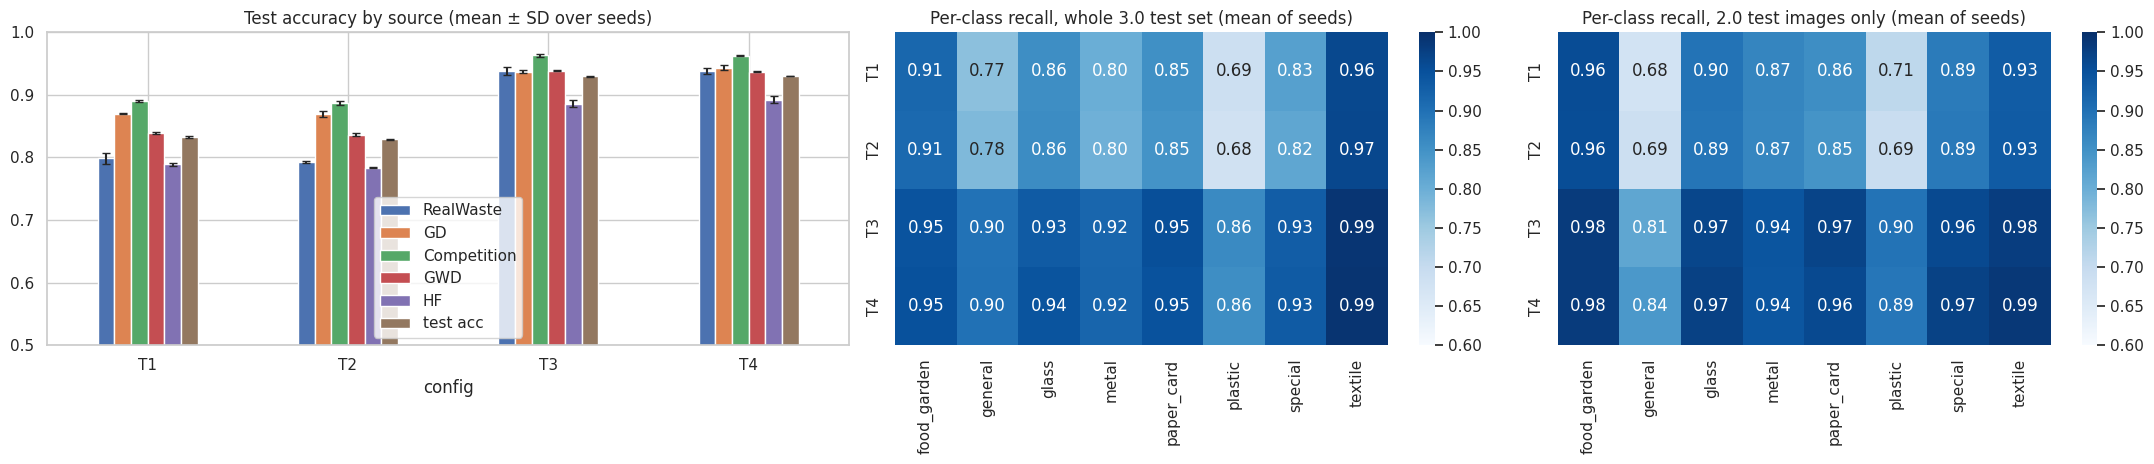

In [8]:

# WHAT: Draw test accuracy by source with seed error bars, and per-class recall as two
#       heatmaps (whole 3.0 test set and the 2.0 test images only).
# WHY:  The bars show whether a configuration's gain is on the real floor photos (RealWaste)
#       or only on the catalogue-style sources, and whether it is bigger than the seed noise.
#       The heatmaps show which classes each configuration finds or misses.
# HOW:  Bar height = mean over seeds; black line = standard deviation. Heatmap = mean recall
#       over seeds, one row per configuration.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
plot_cols = ["RealWaste", "GD", "Competition", "GWD", "HF", "test acc"]
means = per_run.groupby("config")[plot_cols].mean()
sds = per_run.groupby("config")[plot_cols].std(ddof=1)
means.plot.bar(ax=axes[0], rot=0, yerr=sds, capsize=3)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test accuracy by source (mean ± SD over seeds)")
rec = pd.DataFrame({cfg: np.mean([recalls[(cfg, s)] for s in SEEDS], axis=0)
                    for cfg in CONFIGS}, index=class_names).T
sns.heatmap(rec, annot=True, fmt=".2f", cmap="Blues", vmin=0.6, vmax=1, ax=axes[1])
axes[1].set_title("Per-class recall, whole 3.0 test set (mean of seeds)")
rec2 = pd.DataFrame({cfg: np.mean([recalls_v2[(cfg, s)] for s in SEEDS], axis=0)
                     for cfg in CONFIGS}, index=class_names).T
sns.heatmap(rec2, annot=True, fmt=".2f", cmap="Blues", vmin=0.6, vmax=1, ax=axes[2])
axes[2].set_title("Per-class recall, 2.0 test images only (mean of seeds)")
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_test3.png", dpi=150, bbox_inches="tight")
plt.show()


**Finding:** **Freezing costs about 10 points.** The fine-tuned configurations score 93.0% on the whole test set and 0.928 macro-F1, against 83.2% and 0.826 for T1 and 82.9% and 0.822 for T2. The gap is 9 to 10 points on the 2.0 test images (94.2 to 94.5% against 84.8 to 85.1%), 14 points on RealWaste (93.8% against 79.2 to 79.8%) and about 10 points on HF (88.6 to 89.1% against 78.4 to 78.9%), so the real-photo style suffers most, as in 2.0. Plastic recall falls from 0.86 to 0.68 and plastic called metal rises from 38 to 49 photos to 101 to 109. `general` recall falls from 0.90 to 0.77 to 0.78 on the whole test set.

**Resampling against class weights is a tie.** T3 and T4 have the same whole-test accuracy (93.0%), macro-F1 (0.928) and RealWaste score (93.8%). T4 is 0.3 points ahead on the 2.0 images (94.5% against 94.2%) and 0.5 on HF (89.1% against 88.6%), both about the size of the seed standard deviation. Among frozen runs T1 is 0.3 points ahead of T2 in accuracy (83.2% against 82.9%) with a standard deviation of 0.1, small but the same in all three seeds; it does not change any decision.

**The seeds agree.** The standard deviation of whole-test accuracy is 0.001 for every configuration; the largest spreads are on RealWaste (0.005 to 0.009) and HF (0.006), which are small subsets. So the 10-point gap is real and the 0.3-point gaps are not.

**Weak spots.** Plastic is the weakest class for the fine-tuned models (recall 0.86) and `general` on the 2.0 images (0.81 for T3 and 0.84 for T4).

,test acc 2.0,test acc 3.0,test acc delta,test acc SD,test F1 2.0,test F1 3.0,test F1 delta,test F1 SD,RealWaste 2.0,RealWaste 3.0,RealWaste delta,RealWaste SD
config,,,,,,,,,,,,
T1,0.867,0.851,-1.595,0.228,0.864,0.844,-1.968,0.124,0.803,0.798,-0.455,0.934
T2,0.871,0.848,-2.303,0.289,0.868,0.842,-2.603,0.334,0.812,0.792,-1.985,0.145
T3,0.945,0.942,-0.261,0.116,0.944,0.939,-0.513,0.111,0.933,0.938,0.498,0.687
T4,0.944,0.945,0.147,0.257,0.944,0.943,-0.118,0.273,0.937,0.938,0.147,0.467


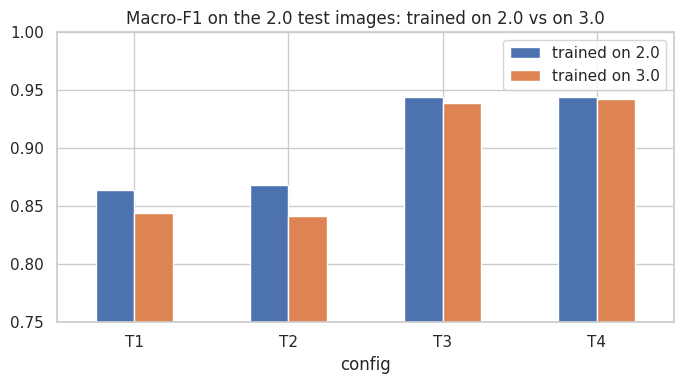

In [9]:
# WHAT: Compare each configuration trained on 3.0 with the same configuration trained on 2.0,
#       using only the 2.0 test images.
# WHY:  This is the main question of the 3.0 work: do 47,400 new images help on the old
#       yardstick? The 2.0 values are the three-seed means printed by the 2.0 ablation
#       notebook for this model, so they are fixed numbers, not retrained here. The 2.0 test
#       images are the same 2,164 images, and the 688 RealWaste test photos are the same too.
#       One configuration has a standard deviation of about 0.2 to 0.4 points over three
#       seeds, so a gap should be compared with that.
# HOW:  Delta = 3.0-trained mean minus 2.0-trained mean, in percentage points. SD is the
#       standard deviation of the 3.0 seeds, in points.
# ------------------------------------------------------------------------------------

REF_2_0 = {
    "T1": {"test acc": 0.867, "test F1": 0.864, "RealWaste": 0.803},
    "T2": {"test acc": 0.871, "test F1": 0.868, "RealWaste": 0.812},
    "T3": {"test acc": 0.945, "test F1": 0.944, "RealWaste": 0.933},
    "T4": {"test acc": 0.944, "test F1": 0.944, "RealWaste": 0.937},
}
ref = pd.DataFrame(REF_2_0).T
g2 = per_run.groupby("config")
ours = pd.DataFrame({"test acc": g2["2.0-test acc"].mean(), "test F1": g2["2.0-test F1"].mean(),
                     "RealWaste": g2["RealWaste"].mean()})
sd = pd.DataFrame({"test acc": g2["2.0-test acc"].std(ddof=1), "test F1": g2["2.0-test F1"].std(ddof=1),
                   "RealWaste": g2["RealWaste"].std(ddof=1)})
ref = ref.loc[ours.index]
cmp = pd.DataFrame(index=ours.index)
for col in ["test acc", "test F1", "RealWaste"]:
    cmp[f"2.0-trained {col}"] = ref[col]
    cmp[f"3.0-trained {col}"] = ours[col]
    cmp[f"delta (points)"] = np.nan if False else None
cmp = pd.DataFrame(index=ours.index)
for col in ["test acc", "test F1", "RealWaste"]:
    cmp[f"{col} 2.0"] = ref[col]
    cmp[f"{col} 3.0"] = ours[col]
    cmp[f"{col} delta"] = (ours[col] - ref[col]) * 100
    cmp[f"{col} SD"] = sd[col] * 100
display(cmp.round(3))

ax = pd.DataFrame({"trained on 2.0": ref["test F1"], "trained on 3.0": ours["test F1"]}).plot.bar(rot=0, figsize=(7, 4))
ax.set_ylim(0.75, 1.0)
ax.set_title("Macro-F1 on the 2.0 test images: trained on 2.0 vs on 3.0")
plt.tight_layout(); plt.show()

**Finding:** **Training on 3.0 did not clearly help the fine-tuned models on the old images.** On the same 2,164 test images, T3 scores 94.2% against 94.5% when trained on 2.0 (-0.3 points, standard deviation 0.1) and T4 94.5% against 94.4% (+0.1, standard deviation 0.2); macro-F1 changes by -0.5 and -0.2 points. On RealWaste, T3 is +0.5 and T4 +0.1 points, inside a standard deviation of 0.5 to 0.7. So the 47,400 new images neither helped nor hurt the fine-tuned model on the old yardstick; their value, if any, is on web-style photos the 2.0 test set does not contain (the new-image accuracy is 92.5 to 92.6%).

**The frozen models got worse**, by 1.6 points (T1) and 2.3 points (T2) on the 2.0 images, and by 2.0 points on RealWaste for T2. These gaps are well beyond their noise (0.2 to 0.3). A plausible reason, not tested here, is that a frozen backbone has only a small output layer to fit, which is pulled towards the web images that now make up most of the training data. This repeats the MobileNet and EfficientNet benchmarks, where 3.0 training did not improve the 2.0 test score.

The T4 seed 42 run scores 93.0% on the whole test set, the same as the 3.0 benchmark of this model, so the ablation reproduces the benchmark recipe.

<a id="section-8"></a>
## Section 8: Selection and Save

**Goal:** Choose the final configuration using the **validation** set only, save the final model, and check that the saved file reloads and scores the same.

In [10]:
# WHAT: Pick the configuration with the highest mean validation macro-F1, then the seed with
#       the highest validation macro-F1 inside it, and save that model as the final model.
# WHY:  Choosing with test results would make the test score optimistic, because the test set
#       would have helped pick the winner. Validation photos are for choices; test photos are
#       for reporting. The same rule is applied to every model in the project.
# HOW:  The final checkpoint keeps its "arch", "config" and "seed" keys, so the comparison
#       notebook and the Pi export can rebuild the right network from the file alone.
# ------------------------------------------------------------------------------------

val_by_cfg = per_run.groupby("config")["val F1"].mean()
print("Mean validation macro-F1 per configuration:")
print(val_by_cfg.round(4).to_string())

BEST_CFG = val_by_cfg.idxmax()                 # override by hand only with a written reason
cand = per_run[per_run["config"] == BEST_CFG]
BEST_SEED = int(cand.loc[cand["val F1"].idxmax(), "seed"])
print(f"\nSelected configuration: {BEST_CFG}  ({CONFIGS[BEST_CFG]})")
print(f"Selected seed (best validation F1): {BEST_SEED}")

final_path = OUT / f"verde3_final_{MODEL}.pth"
shutil.copy(ckpt_path(BEST_CFG, BEST_SEED), final_path)
json.dump(class_names, open(OUT / "class_names.json", "w"), indent=2)
per_run.round(4).to_csv(OUT / f"{MODEL}_results3.csv", index=False)
json.dump({"model": MODEL, "selected_config": BEST_CFG, "selected_seed": BEST_SEED,
           "selection_rule": "highest mean validation macro-F1",
           "seeds": SEEDS, "epochs": EPOCHS, "data": "3.0",
           "configs_finished": list(CONFIGS), "runs_left": left}, open(OUT / f"{MODEL}_summary3.json", "w"), indent=2)

# --- Reload the saved file on its own and re-measure it ---
ck = torch.load(final_path, map_location=device)
net = build_model(pretrained=False).to(device)
net.load_state_dict(ck["model_state"])
_, acc, p_final, y_final = run_epoch(net.eval(), test_loader, eval_criterion)
row = per_run[(per_run["config"] == BEST_CFG) & (per_run["seed"] == BEST_SEED)].iloc[0]
print(f"\nReloaded {final_path.name}: test accuracy {acc:.1%}  (table: {row['test acc']:.1%})")

print("\nSaved files:")
for f in sorted(OUT.glob("verde3_*.pth")):
    print(f"  {f.name:34s} {f.stat().st_size / 1024:8.1f} KB")
if left:
    print(f"\nNOT FINISHED: {len(left)} runs are still to do ({left}); this selection uses only the finished configurations {list(CONFIGS)}.")


Mean validation macro-F1 per configuration:
config
T1    0.8161
T2    0.8132
T3    0.9232
T4    0.9229

Selected configuration: T3  ({'backbone': 'finetune', 'imbalance': 'resample'})
Selected seed (best validation F1): 42



Reloaded verde3_final_effnet_b0.pth: test accuracy 92.9%  (table: 92.9%)

Saved files:
  verde3_effnet_b0_T1_s123.pth        15992.7 KB
  verde3_effnet_b0_T1_s42.pth         15992.3 KB
  verde3_effnet_b0_T1_s7.pth          15992.0 KB
  verde3_effnet_b0_T2_s123.pth        15992.7 KB
  verde3_effnet_b0_T2_s42.pth         15992.3 KB
  verde3_effnet_b0_T2_s7.pth          15992.0 KB
  verde3_effnet_b0_T3_s123.pth        15992.7 KB
  verde3_effnet_b0_T3_s42.pth         15992.3 KB
  verde3_effnet_b0_T3_s7.pth          15992.0 KB
  verde3_effnet_b0_T4_s123.pth        15992.7 KB
  verde3_effnet_b0_T4_s42.pth         15992.3 KB
  verde3_effnet_b0_T4_s7.pth          15992.0 KB
  verde3_final_effnet_b0.pth          15992.3 KB


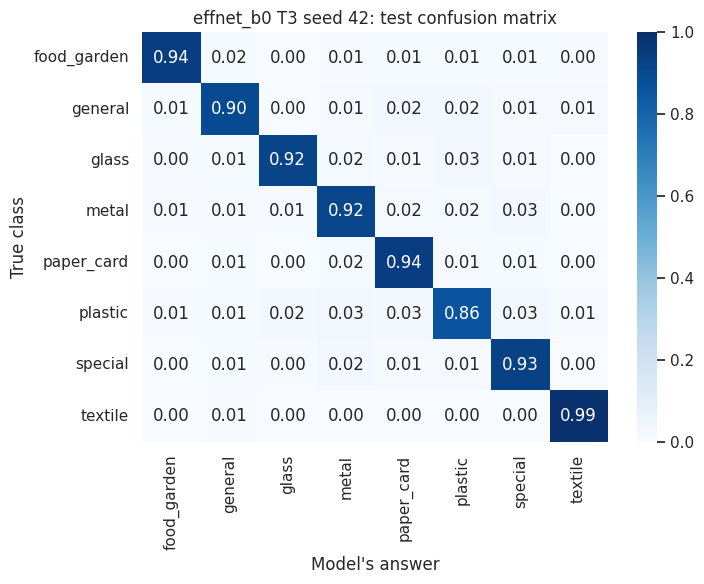

In [11]:
# WHAT: Plot the confusion matrix of the final model on the test set.
# WHY:  The accuracy number hides which classes are mixed up. Rows are the true class,
#       columns the model's answer, so the off-diagonal cells are the mistakes (for example
#       plastic called metal or glass).
# HOW:  Each row is divided by its total, so the numbers are the share of that class's photos.
# ------------------------------------------------------------------------------------

cm = confusion_matrix(y_final, p_final, labels=list(range(len(class_names))))
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
plt.xlabel("Model's answer"); plt.ylabel("True class")
plt.title(f"{MODEL} {BEST_CFG} seed {BEST_SEED}: test confusion matrix")
plt.tight_layout()
plt.savefig(OUT / f"{MODEL}_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** T3 seed 42 was selected on validation. The mean validation macro-F1 is 0.9234 for T3 and 0.9228 for T4, a gap of 0.0006 against seed standard deviations of 0.001 to 0.002, so the selection is a tie and T4 (the benchmark recipe) would have been as good. The reloaded file scores 92.9%, the same as the table (T3 averages 93.0% over its three seeds), and the benchmark's single run of the same model scored 93.0%. In the confusion matrix `plastic` is the weakest class (0.86); its errors are spread evenly, with 3% each called metal, paper_card and special and 2% called glass. `general` is next (0.90), spread thinly (2% each to paper_card and plastic). Glass called plastic (3%) and metal called special (3%) are the other pairs above 2%.

<a id="section-9"></a>
## Section 9: Try Your Own Photos

**Goal:** Check the models on real photos from your own camera, which tells us more than the dataset score. First the real photos are scored automatically (if they are attached; only files named like `glass_bottle_01.jpg` are used); then you can click **Choose file** and pick more photos to see the top-3 guesses of the best seed of each configuration side by side. Below the 60% confidence threshold an answer is shown as "not sure", which is what the app would do. For comparison, the 2.0 models classified 42 to 54% of our 24 photos correctly.

In [12]:
# WHAT: An automatic score on the attached real photos, then a "Choose file" button. Each photo you pick is resized to 224x224 and added to the
#       page with the top-3 guesses of the best seed of every configuration.
# WHY:  Dataset accuracy does not prove the model works on your camera. Adding photos one
#       by one lets you test many items in a row and compare the configurations on each.
# HOW:  The best seed of each configuration is the one with the highest validation F1. After
#       each pick the button is reset, so the next photo (even the same file) is processed
#       as new. "Clear results" wipes the page and the summary log.
# ------------------------------------------------------------------------------------

import io
import ipywidgets as widgets
from IPython.display import display

THRESHOLD = 0.60
nets = {}
for cfg in CONFIGS:
    part = per_run[per_run["config"] == cfg]
    nets[cfg] = load_net(cfg, int(part.loc[part["val F1"].idxmax(), "seed"]))[0]
log = []                                    # one row per photo, for a summary table

def prepare(img):
    """Any PIL image -> normalised [3, 224, 224] tensor (same steps as the Pi and the app)."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return eval_transform(img)

import re
from collections import Counter

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def label_of(path):
    stem = path.stem.lower()
    for c in sorted(class_names, key=len, reverse=True):
        if stem.startswith(c + "_"):
            return c
    return None

skip_dirs = [ROOT2, ROOT3]
# Our own photos are named like glass_bottle_01.jpg: all lowercase, class, item, number.
# Files from other datasets (Metal_101.jpg, plastic_12.jpg) do not fit this pattern.
OWN_NAME = re.compile(r"^(?:" + "|".join(class_names) + r")_[a-z0-9_]+_\d{1,3}$")
candidates = [p for p in INPUT.rglob("*")
              if p.suffix.lower() in IMAGE_EXTS
              and not any(p.is_relative_to(d) for d in skip_dirs)
              and label_of(p) and OWN_NAME.match(p.stem)]
# A folder with many matching files is another dataset, not our own photos, so it is
# ignored and reported. (We have 24 real photos.)
MAX_PHOTOS_PER_FOLDER = 60
folder_size = Counter(p.parent for p in candidates)
photo_paths = sorted(p for p in candidates if folder_size[p.parent] <= MAX_PHOTOS_PER_FOLDER)
ignored = {str(d): n for d, n in folder_size.items() if n > MAX_PHOTOS_PER_FOLDER}
if ignored:
    print("Ignored folders that look like datasets, not own photos:", ignored)
print(f"Real photos found: {len(photo_paths)}")

if photo_paths:
    rows_ = []
    for p in photo_paths:
        with Image.open(p) as im_:
            x = prepare(im_).unsqueeze(0).to(device)
        row = {"photo": p.name[:30], "true": label_of(p)}
        for name, net in nets.items():
            with torch.no_grad():
                pr = torch.softmax(net(x), 1)[0].cpu().numpy()
            row[name] = class_names[pr.argmax()]
            row[name + " conf"] = round(float(pr.max()), 2)
        rows_.append(row)
    photo_df = pd.DataFrame(rows_)

    summ = []
    for name in nets:
        ok = photo_df[name] == photo_df["true"]
        sure = photo_df[name + " conf"] >= THRESHOLD
        summ.append({"config": name, "correct": ok.mean(), "correct and sure": (ok & sure).mean(),
                     "not sure": (~sure).mean(), "wrong and sure": ((~ok) & sure).mean()})
    photo_summary = pd.DataFrame(summ).set_index("config")
    print(f"Accuracy on {len(photo_df)} real photos (2.0 models: 42 to 54%):")
    display((photo_summary * 100).round(1))
    print("Correct photos per class:")
    display(pd.DataFrame({n: (photo_df[n] == photo_df["true"]).groupby(photo_df["true"]).sum() for n in nets})
            .assign(photos=photo_df["true"].value_counts()))
    print("Every photo:")
    display(photo_df)
else:
    print("No real photos attached; skipping the automatic score. Use the upload button below instead.")
    photo_summary = None

def get_files(value):
    """Works with older (dict) and newer (tuple) ipywidgets."""
    if isinstance(value, dict):
        return [(n, bytes(f["content"])) for n, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]

def show_photo(name, data):
    raw = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(raw).convert("RGB")
    x = prepare(img).unsqueeze(0).to(device)
    row = {"photo": name[:30]}
    fig, axes = plt.subplots(1, 1 + len(nets), figsize=(3.4 * (1 + len(nets)), 3.4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(name[:28], fontsize=9)
    for ax, (cfg, net) in zip(axes[1:], nets.items()):
        with torch.no_grad():
            p = torch.softmax(net(x), 1)[0].cpu().numpy()
        top = np.argsort(-p)[:3][::-1]
        ax.barh([class_names[i] for i in top], p[top])
        ax.set_xlim(0, 1)
        answer = class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"
        ax.set_title(f"{cfg}: {answer} {p.max():.0%}", fontsize=9)
        row[cfg] = f"{answer} {p.max():.0%}"
    log.append(row)
    plt.tight_layout(); plt.show()

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Choose file")
clear_btn = widgets.Button(description="Clear results")
out = widgets.Output()

def on_upload(change):
    files = get_files(uploader.value)
    if not files:                           # the reset below triggers this once more
        return
    with out:
        for name, data in files:
            show_photo(name, data)
    uploader.value = {} if isinstance(uploader.value, dict) else ()   # ready for the next photo

def on_clear(_):
    out.clear_output()
    log.clear()

uploader.observe(on_upload, names="value")
clear_btn.on_click(on_clear)
display(widgets.HBox([uploader, clear_btn]), out)

Real photos found: 24
Accuracy on 24 real photos (2.0 models: 42 to 54%):


,correct,correct and sure,not sure,wrong and sure
config,,,,
T1,62.5,37.5,37.5,25.0
T2,54.2,29.2,45.8,25.0
T3,50.0,37.5,29.2,33.3
T4,45.8,41.7,25.0,33.3


Correct photos per class:


,T1,T2,T3,T4,photos
true,,,,,
food_garden,2,2,2,2,2
general,0,0,0,0,7
glass,1,1,1,1,1
metal,3,3,2,2,3
paper_card,2,2,2,2,3
plastic,2,1,1,1,2
special,0,0,0,0,1
textile,5,4,4,3,5


Every photo:


,photo,true,T1,T1 conf,T2,T2 conf,T3,T3 conf,T4,T4 conf
0,food_garden_bananas_01.jpeg,food_garden,food_garden,0.50,food_garden,0.45,food_garden,0.39,food_garden,0.63
1,food_garden_flowers_01.jpeg,food_garden,food_garden,0.66,food_garden,0.57,food_garden,0.78,food_garden,0.92
2,general_ceramic_mug_01.jpeg,general,plastic,0.75,plastic,0.69,special,0.88,special,0.76
3,general_hot_water_bottle_01.jp,general,plastic,0.79,plastic,0.66,glass,0.34,glass,0.50
4,general_keyboard_01.jpeg,general,special,0.82,special,0.81,special,0.91,special,0.89
5,general_mouse_01.jpeg,general,special,0.87,special,0.90,special,0.93,special,0.81
6,general_watch_01.jpeg,general,metal,0.80,metal,0.80,metal,0.82,metal,0.91
7,general_wipes_pack_01.jpeg,general,paper_card,0.77,paper_card,0.78,paper_card,0.61,metal,0.47
8,general_wrapper_noodles_01.jpe,general,metal,0.42,metal,0.40,metal,0.74,metal,0.57
9,glass_jug_01.jpeg,glass,glass,0.65,glass,0.60,glass,0.87,glass,0.86


Output()

**Finding:** **The 24 real photos do not rank the configurations like the dataset does.** Correct: T1 15 of 24 (62.5%), T2 13 (54.2%), T3 12 (50.0%), T4 11 (45.8%), against 42 to 54% for the 2.0 models and 41.7 to 45.8% for the 3.0 MobileNets. The frozen models are "not sure" more often (38 to 46% of photos against 25 to 29%) and are wrong and sure on 6 photos against 8 for the fine-tuned ones. The ranking is the opposite of the dataset results, but the gap between T1 and T4 is four photos, and the noise on 24 photos is about 10 points, so the ordering should not be trusted. The fine-tuned models lose mainly on the steel flask (called plastic, but unsure), the yogurt tub, the toilet roll (T4 says general at 76%), the teddy bear (T3 and T4 say food_garden at 70% and 84%) and, for T4, the handbag (paper_card at 68%); the frozen models were right or unsure on those.

**Labels need a decision.** None of the seven `general` photos is right for any configuration (0 of 7). The keyboard and the mouse are called `special` by every configuration with 81 to 93% confidence, which is correct under our rules (electricals go to `special`); if both are relabelled `special`, every configuration gains two photos (T1 17, T2 15, T3 14, T4 13 of 24). The watch is called metal by all four, which is wrong under the same rule, and the battery (`special`) is called metal or paper_card by all four, but there is only one battery photo. Electricals and batteries remain a gap that more labelled Pi photos will fix better than a different configuration. All four configurations get the plastic water bottle, the glass jug, the cereal box and the T-shirt right.

<a id="section-10"></a>
## Section 10: Summary and Limitations

**Summary:** Fine-tuning is necessary (93.0% against 83% on the whole test set, 93.8% against 79 to 80% on RealWaste); how class imbalance is handled is not (T3 and T4 tie at 93.0% and macro-F1 0.928). T3 seed 42 was selected on validation, effectively tied with T4: 92.9% on the whole test set, 94.2% on the 2.0 images and about 93.8% on RealWaste, with a 16.1 MB file and 37 ms per photo on the Kaggle CPU. Training on 3.0 did not clearly improve the fine-tuned model on the 2.0 test images (-0.3 and +0.1 points) and hurt the frozen ones. The weak classes are plastic (recall 0.86) and `general`. The real-photo score (46 to 62%) is a rough check on 24 photos; it does not separate the configurations, and the labels of the keyboard, mouse and watch need a decision first.

**How to use the result**
1. Commit this notebook (Save & Run All) so the saved files exist as notebook output. If it stopped early (`NOT FINISHED` in Section 5), save the output and run it again in a new session with that output attached.
2. Attach this notebook's output to the **real-photo comparison notebook**, which scores every saved checkpoint on the same Pi photos. The files are now named `verde3_*.pth`, so check that notebook's file pattern.
3. `verde3_final_effnet_b0.pth` stores the model name, configuration and seed, so a later notebook rebuilds the network with `build_model()` and does not have to assume one architecture.
4. Measure the real inference time on the Raspberry Pi before exporting with ExecuTorch.

**Limitations**
- Three seeds give a rough estimate of the noise, not a precise one. Gaps smaller than one standard deviation should not drive a decision.
- Every configuration uses the same learning rate and 12 epochs, to keep the test fair. Frozen runs in particular might do better with a higher learning rate or more epochs.
- The 3.0 test set is mostly new images (GWD and HF), so its accuracy is not comparable with the 2.0 ablation. Only the 2.0-test subset is a like-for-like yardstick.
- The new images carry label noise that was judged by eye, not removed: the `special` class includes blank factory bottles, some incandescent bulbs and adverts, and scrap-yard heaps. A model can score well on this data and still learn some of that noise.
- The 24-photo ranking (frozen above fine-tuned) is the opposite of the dataset ranking. With one photo worth 4 points it is noise, and the keyboard and mouse are labelled `general` although our rules treat electricals as `special`, so the score depends on how those photos are labelled.
- Dataset test accuracy is flattered by catalogue-style photos. RealWaste and the 24 real photos are the better guide, but 24 photos are a rough check, not a score.
- The RealWaste boost of 2 was kept from 2.0 and was not re-tuned for 3.0, where RealWaste is a smaller share of the data.
- CPU times come from a Kaggle CPU, not a Raspberry Pi. Use them to compare models with each other.
- A network cannot learn items it has never seen, such as watches, mice and other electricals. More Pi training photos of those will help more than a different configuration.
- The ablation is run on EfficientNet-B0 only, so the conclusions about freezing and imbalance handling may not carry over exactly to other architectures.